### Mathematically, the expectation of LGD in a Beta regression model is:

$$ E(\text{LGD}) = \mu = \frac{e^{X\beta}}{1 + e^{X\beta}} $$

where:
- $(X\beta)$ is the linear predictor,
- The logit link function ensures $(\mu)$ stays in $((0, 1))$,
- $(\mu)$ is the mean of the Beta distribution, which is the predicted LGD.

Since Beta regression models both the mean and dispersion (variance) of the response, it provides a more flexible and realistic estimation of LGD than linear regression.



In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Sample dataset
data = {
    "LGD": [0.05, 0.15, 0.35, 0.60, 0.80, 0.95],  # LGD values (strictly between 0 and 1)
    "Collateral": [100, 200, 150, 300, 250, 180],
    "LTV": [0.8, 0.7, 0.9, 0.6, 0.85, 0.95],
    "Maturity": [5, 10, 7, 15, 12, 8]
}

df = pd.DataFrame(data)

# Apply transformation to ensure LGD stays strictly within (0,1)
df["LGD_adj"] = (df["LGD"] * (len(df) - 1) + 0.5) / len(df)

# Fit Beta regression model using Logit link function
model = smf.glm("LGD_adj ~ Collateral + LTV + Maturity",
                data=df,
                family=sm.families.Binomial()).fit()

# Print results
print(model.summary())

# Predict LGD values
df["Predicted_LGD"] = model.predict(df)
print(df[["LGD", "Predicted_LGD"]])

                 Generalized Linear Model Regression Results                  
Dep. Variable:                LGD_adj   No. Observations:                    6
Model:                            GLM   Df Residuals:                        2
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2.1746
Date:                Tue, 25 Feb 2025   Deviance:                     0.054988
Time:                        09:52:20   Pearson chi2:                   0.0588
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2740
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.6928     29.596     -0.057      0.9

### The Weibull distribution can be used in LGD (Loss Given Default) estimation to model the distribution of losses. The Weibull distribution is flexible and can model various shapes of data distributions, making it suitable for different types of loss data.

### Weibull Distribution in LGD Estimation

The Weibull distribution is defined by two parameters:
- **Shape parameter (k)**: Determines the shape of the distribution.
- **Scale parameter (λ)**: Determines the scale of the distribution.

The probability density function (PDF) of the Weibull distribution is given by:

$$[ f(x; k, \lambda) = \frac{k}{\lambda} \left(\frac{x}{\lambda}\right)^{k-1} e^{-(x/\lambda)^k}] $$

Usage in LGD Estimation

1. Modeling Losses: The Weibull distribution can be used to model the distribution of losses given default. This is useful when the loss data exhibits skewness or kurtosis that is not well captured by other distributions.

2. Parameter Estimation: The parameters of the Weibull distribution (shape and scale) can be estimated using maximum likelihood estimation (MLE) or other fitting techniques based on historical loss data.

3. Prediction: Once the parameters are estimated, the Weibull distribution can be used to predict the probability of different levels of loss given default.



Shape parameter: 2.7840197890107374
Scale parameter: 0.28180727480464784


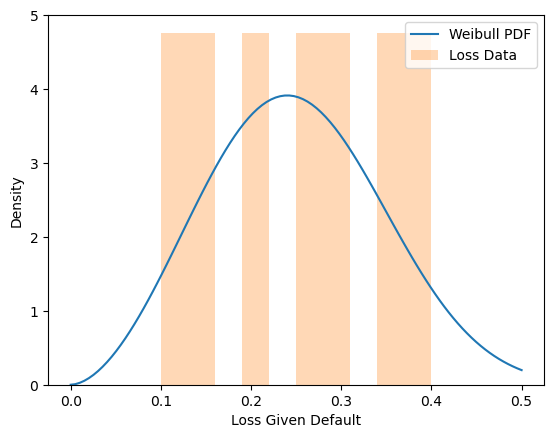

In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Example loss data
loss_data = np.array([0.1, 0.2, 0.15, 0.3, 0.25, 0.4, 0.35])

# Fit Weibull distribution to the data
shape, loc, scale = stats.weibull_min.fit(loss_data, floc=0)

# Print the estimated parameters
print(f"Shape parameter: {shape}")
print(f"Scale parameter: {scale}")

# Generate a range of values for plotting the PDF
x = np.linspace(0, 0.5, 100)
pdf = stats.weibull_min.pdf(x, shape, loc, scale)

# Plot the PDF
plt.plot(x, pdf, label='Weibull PDF')
plt.hist(loss_data, bins=10, density=True, alpha=0.3, label='Loss Data')
plt.xlabel('Loss Given Default')
plt.ylabel('Density')
plt.legend()
plt.show()